# Latent-TTA mit FP / FN als Signal — Stand 20.11.

**Frage seit dem letzten Meeting:** Kann eine *gelernte* Schätzung der False Positives (FP) und False
Negatives (FN) der U-Net-Maske μ̂ als label-freies Ziel der Latent-TTA ersetzen?

**Setup (unverändert):** PMRI, Test-Domäne, eingefrorene U-Net, pro Bild kanalweise Affine γ·z + β auf
den latenten Features an den Swivels [0, 17] (nach der InstanceNorm), Adam lr 0.01, 100 Schritte.
Zahlen sind Mittel über die 5 Paare Score-Predictor `cleanHalf_k` ↔ FP/FN-Head `fpfn_k`. Dice ohne TTA:
0.677 (3T→1.5T) / 0.642 (PROMISE12) / 0.526 (1.5T→3T). Alle neuen Head-Experimente nur auf **3T→1.5T**.

Alle Zahlen und Abbildungen werden unten aus `results/` und `logs/` berechnet. Die ausführliche
Analyse steht in [`fpfn_findings.ipynb`](../../fpfn_findings.ipynb), die Literatur in
[`docs/literatur_signal.md`](../../../../docs/literatur_signal.md), die Details zum Head in
[`docs/fpfn_head_details.md`](../../../../docs/fpfn_head_details.md). Die Abbildungen liegen
zusätzlich als PNG in `results/plots_meeting_20_11/`.

## Stand beim letzten Meeting (10.11.)

| Bis 10.11. gelaufen (3T→1.5T / PROMISE12 / 1.5T→3T) | Dice nach TTA |
|---|---|
| μ̂ allein | 0.753 / 0.702 / 0.538 |
| Größen-Orakel (Zielgröße einmal aus echten FP₀/FN₀; ±30 % Rauschen egal) | 0.783 / 0.742 / 0.590 |
| μ̂ + echte FP/FN, *getrennt* log(1+FP) + log(1+FN) | 0.707 / 0.673 / 0.562 |
| μ̂ + echte FP/FN, *gemeinsam* log(1+FP+FN) | **0.889 / 0.875 / 0.677** |
| μ̂ + gelernter FP/FN-Head (hart / weich / weich + down), nur 3T→1.5T | 0.679 / 0.645 / 0.627 |

→ Echte FP/FN sind ein sehr starkes Signal, der gelernte Head war schlechter als μ̂ allein
(FN ~5× unterschätzt).

**Feedback vom 10.11.:** μ̂ und κ weglassen, *nur* FP/FN nutzen (FP = FN = 0 ⇔ Dice = 1, kein λ
abzustimmen), adversariale Störungen weiter im Eingaberaum.

## Was wir seitdem herausgefunden haben

1. **Nur FP/FN (ohne μ̂) funktioniert mit echten Zahlen, nicht mit dem Head** (Abb. 2, 3). Echte
   Zahlen: 0.886 — genauso gut wie mit μ̂ (0.889), μ̂ bringt bei perfektem FP/FN-Signal also nichts
   dazu. Nur gelernter Head: 0.651, *unter* dem Start; die TTA senkt die vorhergesagten FN, während die
   echten FN steigen.
2. **Die Heads generalisieren nicht, nicht einmal in der eigenen Domäne** (Abb. 4). r(log FN) ≈ 0.85
   auf den Trainingsbildern der U-Net, ≤ 0.2 auf der Validierung derselben Domäne. Auf ihren
   Trainingsbildern macht die U-Net kaum Fehler (Dice 0.92–0.95); der Head sieht nie realistische Fehler.
3. **Änderungen am Training haben nicht geholfen** (Abb. 4, 5): getrennte Adversaries (+∇FP̂ / +∇FN̂),
   zwei komplett getrennte Heads, weiche Zählung, ein „down“-Adversary. Beide Adversaries erhöhen vor
   allem die echten FN — FN-Richtungen wurden also gesehen.
4. **Nebenbefund: der LR-Scheduler hat jedes Training um Epoche ~100 eingefroren** (Abb. 6) — alle
   FP/FN-Heads **und der μ̂-Predictor** enden bei lr 3.2e-9. Ein früherer Checkpoint wäre nicht besser
   gewesen, ein Neutraining mit dem Scheduler auf dem sauberen Loss steht aber aus.
5. **Mechanismus:** Beim Orakel ist ∂FP/∂p = (1 − g) und ∂FN/∂p = −g, der Gradient *ist die
   Label-Karte* und sagt jedem Pixel, wohin es muss. Beim gelernten Head läuft der Gradient durch seine
   eigenen, nie trainierten Steigungen — über die Logits und zusätzlich über die Features von Schicht 17,
   die die Affine an Schicht 0 verändert. Gleicher Wert ≠ gleiche Steigung.
6. **Pseudo-Label-Orakel** (Abb. 7): Orakel-Formel mit einer festen, verschlechterten Label-Karte ĝ.
   Der Gewinn fällt gleichmäßig mit der Qualität von ĝ; schon mit 50 % korrigierten Fehlern schlägt die
   TTA (0.765) μ̂ allein. **Aber die TTA landet immer unter ĝ selbst** — ein gutes ĝ wäre direkt als
   Segmentierung besser.
7. **Restlücke zum Dice-Orakel = verpasste Prostatas** (Abb. 8): Bilder mit Dice < 0.1 vor der TTA
   (12 / 9 / 25 %). Die leere Maske ist ein lokales Minimum von log(1+FP+FN).
8. **Literatur:** Niemand nutzt eine gelernte FP/FN-Regression als *differenzierbares* TTA-Ziel. Wo
   Fehler- bzw. Qualitätsschätzungen in die Adaptation eingehen, werden sie zu festen Pseudo-Labels oder
   Gewichten (Karani et al. 2021, DEP-Net 2022, TEGDA 2025) — die Struktur unseres Pseudo-Label-Orakels.

**Vorschlag:** zurück zu μ̂ als einsetzbarem Signal, FP/FN nur noch als *Struktur* (Pseudo-Label ĝ),
nicht als gelernte Zahl. Details am Ende.

In [1]:
%matplotlib inline
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
import pickle, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
warnings.filterwarnings('ignore')

ROOT = Path.cwd().resolve()
while not ((ROOT / 'results').is_dir() and (ROOT / 'src').is_dir()):
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Notebook bitte innerhalb des isbi26-implementation-Repos ausführen')
    ROOT = ROOT.parent
RES, LOGS = ROOT / 'results', ROOT / 'logs'
SPLITS = {'threet-to-onepointfivet': '3T→1.5T', 'promise12': 'PROMISE12', 'onepointfivet-to-threet': '1.5T→3T'}
_CACHE = {}

def load_pkl(f):
    f = str(f)
    if f not in _CACHE:
        with open(f, 'rb') as fh:
            _CACHE[f] = pickle.load(fh)
    return _CACHE[f]

def tta_files(run, split):
    return sorted(RES.glob(f'{run}/pmri_{split}_*cleanHalf_*/latent_tta.pkl'))

def get_t(e, key, col=None):
    """per-image tensor (float) or None; col selects a step from a *_per_step tensor"""
    v = e.get(key)
    if v is None or not torch.is_tensor(v) or v.numel() == 0:
        return None
    v = v.float()
    return v[:, col] if col is not None else v

def tta_row(run, split, dom='test'):
    per_ckpt = []
    for f in tta_files(run, split):
        e = load_pkl(f)['evaluation'][f'{split}_{dom}']
        size_after = get_t(e, 'size_after')
        if size_after is None:
            size_after = get_t(e, 'hard_size_per_step', -1)
        fp_b = get_t(e, 'fp_before'); fp_a = get_t(e, 'fp_after'); fn_b = get_t(e, 'fn_before'); fn_a = get_t(e, 'fn_after')
        fpp = get_t(e, 'fp_pred_per_step'); fnp = get_t(e, 'fn_pred_per_step')
        nan = float('nan'); m = lambda t: float(t.mean()) if t is not None else nan
        per_ckpt.append({
            'before': m(e['dice_before'].float()), 'after': m(e['dice_after'].float()),
            'best step': m(e['best_dice'].float()),
            'worse %': 100 * m((e['dice_after'] < e['dice_before'] - 0.01).float()),
            'empty %': 100 * m((size_after == 0).float()) if size_after is not None else nan,
            'FP before': m(fp_b), 'FP after': m(fp_a), 'FN before': m(fn_b), 'FN after': m(fn_a),
            'FP_hat before': m(fpp[:, 0]) if fpp is not None else nan,
            'FP_hat after': m(fpp[:, -1]) if fpp is not None else nan,
            'FN_hat before': m(fnp[:, 0]) if fnp is not None else nan,
            'FN_hat after': m(fnp[:, -1]) if fnp is not None else nan,
        })
    if not per_ckpt:
        return None
    df = pd.DataFrame(per_ckpt)
    row = df.mean().to_dict()
    row['after ± (ckpts)'] = df['after'].std(ddof=0)
    row['n ckpts'] = len(per_ckpt)
    return row

def tta_table(runs, splits=SPLITS, dom='test', cols=None):
    rows = []
    for label, run in runs:
        for s in splits:
            r = tta_row(run, s, dom)
            if r is not None:
                rows.append({'run': label, 'split': SPLITS[s], **r})
    df = pd.DataFrame(rows).set_index(['split', 'run'])
    return df[cols] if cols else df

def head_files(split, tag):
    return sorted(RES.glob(f'fpfn_head/pmri_{split}_*-{tag}_[0-9]_*/eval_data.pkl'))

def head_table(entries):
    """entries: [(label, split, tag)] -> metrics per domain, mean over the 5 heads"""
    rows = []
    for label, split, tag in entries:
        evs = [load_pkl(f)['evaluation'] for f in head_files(split, tag)]
        for dom in ('train', 'val', 'test'):
            vals = []
            for ev in evs:
                e = ev[f'{split}_{dom}']; s = e['summary']
                p = torch.expm1(e['pred'].float().clamp_min(0)); t = torch.expm1(e['target'].float())
                vals.append({'r log FP': s['corr_log_fp'], 'r log FN': s['corr_log_fn'],
                             'MAE log FP': s['mae_log_fp'], 'MAE log FN': s['mae_log_fn'],
                             'FP_hat / FP': float(p[..., 0].mean() / t[..., 0].mean()),
                             'FN_hat / FN': float(p[..., 1].mean() / t[..., 1].mean()),
                             'r Dice (implied)': s['corr_dice'], 'U-Net Dice': float(e['dice'].float().mean())})
            rows.append({'split': SPLITS[split], 'head': label, 'domain': dom, 'n heads': len(evs),
                         **pd.DataFrame(vals).mean().to_dict()})
    return pd.DataFrame(rows).set_index(['split', 'head', 'domain'])

ADV_LINE = re.compile(r'\[epoch (\d+)\]\s+(FP|FN) adversary: factor ([\d.]+) grad norm \S+ '
                      r'true Dice drop ([+-][\d.]+) true dlog FP ([+-][\d.]+) FN ([+-][\d.]+)')

def split_adversary_table(tag='fpfnsplit', ranges=((40, 70), (70, 150), (150, 250), (250, 400))):
    recs = []
    for f in sorted(LOGS.glob(f'train_{tag}_head_[0-9].log')):
        for line in open(f, errors='ignore'):
            for m in ADV_LINE.finditer(line):
                recs.append({'epoch': int(m.group(1)), 'adversary': m.group(2), 'step factor': float(m.group(3)),
                             'true Dice drop': float(m.group(4)), 'rise log(1+FP)': float(m.group(5)),
                             'rise log(1+FN)': float(m.group(6))})
    df = pd.DataFrame(recs)
    df['epochs'] = pd.cut(df['epoch'], [r[0] for r in ranges] + [ranges[-1][1]], right=False,
                          labels=[f'{a}-{b - 1}' for a, b in ranges])
    return df.groupby(['epochs', 'adversary'], observed=True)[
        ['step factor', 'true Dice drop', 'rise log(1+FP)', 'rise log(1+FN)']].mean()

def per_step_means(run, split, dom='test', keys=('dice_per_step', 'fp_hard_per_step', 'fn_hard_per_step',
                                                  'fp_pred_per_step', 'fn_pred_per_step')):
    out = {}
    for k in keys:
        arr = [get_t(load_pkl(f)['evaluation'][f'{split}_{dom}'], k) for f in tta_files(run, split)]
        arr = [a for a in arr if a is not None]
        if arr:
            out[k] = torch.cat(arr).mean(0).numpy()
    return out

def emptied_table(runs, splits=SPLITS, dom='test'):
    rows = []
    for label, run in runs:
        for s in splits:
            fs = tta_files(run, s)
            if not fs:
                continue
            n = tot = 0; dice_b = []; gt = []; gt_all = []
            for f in fs:
                e = load_pkl(f)['evaluation'][f'{s}_{dom}']
                if 'size_after' not in e:
                    continue
                m = e['size_after'] == 0
                n += int(m.sum()); tot += m.numel()
                dice_b.append(e['dice_before'][m].float()); gt.append(e['size_gt'][m].float()); gt_all.append(e['size_gt'].float())
            if tot:
                db = torch.cat(dice_b); g = torch.cat(gt)
                rows.append({'split': SPLITS[s], 'run': label, 'emptied %': 100 * n / tot,
                             'their Dice before (mean)': float(db.mean()) if n else float('nan'),
                             'their GT size (median)': float(g.median()) if n else float('nan'),
                             'GT size all images (median)': float(torch.cat(gt_all).median())})
    return pd.DataFrame(rows).set_index(['split', 'run'])


# ---- Darstellung ---------------------------------------------------------------------------------
pd.set_option('display.max_columns', 40)
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6'
NEUTRAL = '#b5b3ad'
# Rollen wie in den Meeting-Notebooks: μ̂ blau, Orakel grün, Ausgang grau; neu: FP/FN-Heads orange
GREEN, RED, REF, START = '#1baf7a', '#e34948', '#52514e', '#898781'
C_MU, C_HEAD, C_ORACLE = BLUE, ORANGE, GREEN
SEQ = ['#104281', '#1c5cab', '#3987e5', '#86b6ef']
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'text.color': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
                     'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'figure.titlesize': 12,
                     'figure.titleweight': 'bold'})
SPLIT_ORDER = list(SPLITS)
T15 = 'threet-to-onepointfivet'

def evals(run, split, dom='test'):
    return [load_pkl(f)['evaluation'][f'{split}_{dom}'] for f in tta_files(run, split)]

def after_per_ckpt(run, split, dom='test'):
    return [float(e['dice_after'].float().mean()) for e in evals(run, split, dom)]

def before_dice(split, run='latent_tta_prenorm'):
    return float(evals(run, split)[0]['dice_before'].float().mean())

def label_bars(ax, bars, fmt='{:.3f}', pad=0.004, horizontal=True):
    for b in bars:
        if horizontal:
            ax.text(b.get_width() + pad, b.get_y() + b.get_height() / 2, fmt.format(b.get_width()),
                    va='center', ha='left', fontsize=9, color=INK)
        else:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + pad, fmt.format(b.get_height()),
                    va='bottom', ha='center', fontsize=8, color=INK)

def start_line(ax, x, label='Dice nach TTA'):
    ax.axvline(x, color=START, ls='--', lw=1.2, zorder=1)
    ax.set_xlabel(f'{label}   (gestrichelt: ohne TTA = {x:.3f})')

# ---- Fehlerkarten --------------------------------------------------------------------------------
C_TP, C_FP, C_FN = np.array([0.11, 0.69, 0.48]), np.array([0.89, 0.29, 0.28]), np.array([0.16, 0.47, 0.84])
ERR_LEGEND = [mpatches.Patch(color=C_TP, label='richtig (TP)'), mpatches.Patch(color=C_FP, label='FP (zu viel)'),
              mpatches.Patch(color=C_FN, label='FN (fehlt)')]

def dice_np(p, g):
    s = p.sum() + g.sum()
    return 1.0 if s == 0 else 2 * (p & g).sum() / s

def crop_box(masks, pad=28):
    m = np.zeros_like(masks[0], dtype=bool)
    for x in masks:
        m |= x.astype(bool)
    if not m.any():
        H, W = m.shape
        return slice(H // 4, 3 * H // 4), slice(W // 4, 3 * W // 4)
    ys, xs = np.where(m)
    H, W = m.shape
    cy, cx = (ys.min() + ys.max()) // 2, (xs.min() + xs.max()) // 2
    h = max(ys.max() - ys.min(), xs.max() - xs.min()) // 2 + pad
    h = max(h, 48)
    return slice(max(cy - h, 0), min(cy + h, H)), slice(max(cx - h, 0), min(cx + h, W))

def error_panel(ax, img, pred, gt, title, box=None, alpha=0.55):
    img = img.astype(np.float32)
    lo, hi = np.percentile(img, [1, 99])
    img = np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)
    rgb = np.repeat(img[..., None], 3, -1)
    p, g = pred.astype(bool), gt.astype(bool)
    for m, c in ((p & g, C_TP), (p & ~g, C_FP), (~p & g, C_FN)):
        rgb[m] = (1 - alpha) * rgb[m] + alpha * c
    if box is not None:
        rgb = rgb[box]
    ax.imshow(rgb, interpolation='nearest')
    ax.set_title(f'{title}\nDice {dice_np(p, g):.2f}', fontsize=9, fontweight='normal')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

def example(run, split, idx, key='pred_final', ckpt=0):
    fs = tta_files(run, split)
    if not fs:
        return None
    ex = load_pkl(fs[ckpt])['evaluation'][f'{split}_test'].get('examples', {})
    if 'index' not in ex or len(ex['index']) == 0:
        return None
    pos = (ex['index'] == idx).nonzero()
    if len(pos) == 0 or key not in ex:
        return None
    k = int(pos[0, 0])
    return {'image': ex['image'][k].float().numpy(), 'target': ex['target'][k].numpy().astype(bool),
            'before': ex['pred_before'][k].numpy().astype(bool), 'pred': ex[key][k].numpy().astype(bool)}

print('Repo:', ROOT)

FIG_DIR = RES / 'plots_meeting_20_11'          # PNGs für die Folien
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

Repo: /root/workspace/repos/isbi26-implementation


## 1 · Überblick

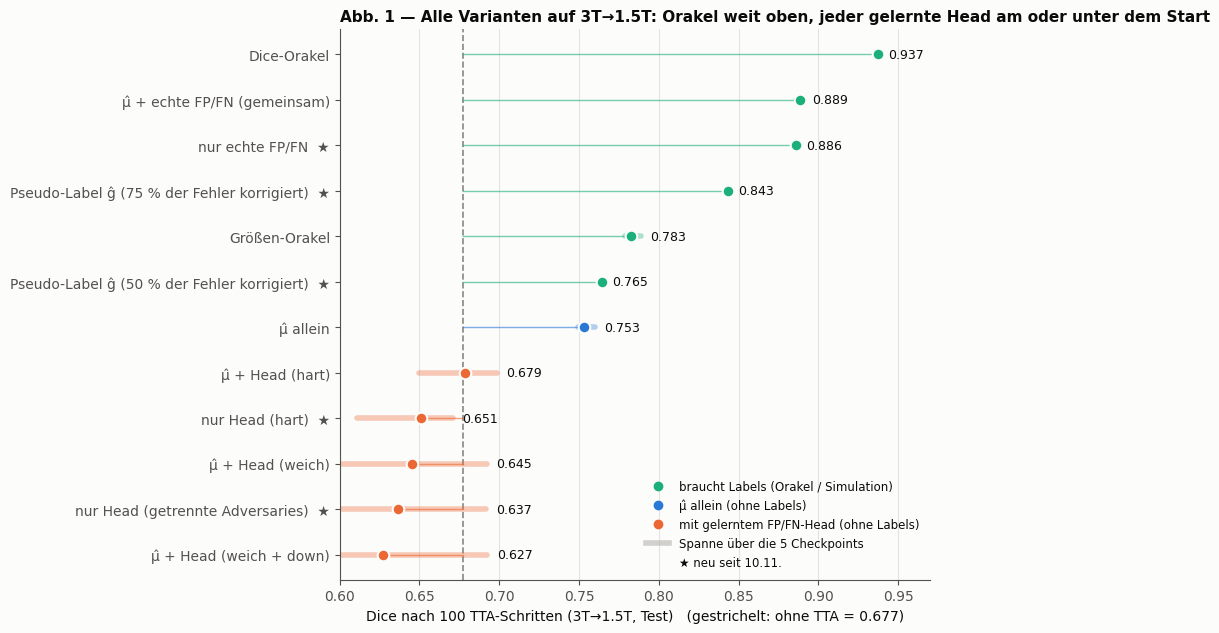

In [2]:
OVERVIEW = [
    # Name, Lauf, Gruppe, neu seit 10.11.?
    ('Dice-Orakel', 'latent_tta_oracle', 'Orakel', False),
    ('μ̂ + echte FP/FN (gemeinsam)', 'latent_tta_mu_fpfn_joint_w1.0', 'Orakel', False),
    ('nur echte FP/FN', 'latent_tta_fpfnonly_oracle', 'Orakel', True),
    ('Pseudo-Label ĝ (75 % der Fehler korrigiert)', 'latent_tta_pseudo_recall0.75', 'Orakel', True),
    ('Pseudo-Label ĝ (50 % der Fehler korrigiert)', 'latent_tta_pseudo_recall0.5', 'Orakel', True),
    ('Größen-Orakel', 'latent_tta_mu_size_w1.0', 'Orakel', False),
    ('μ̂ allein', 'latent_tta_prenorm', 'ohne Labels', False),
    ('μ̂ + Head (hart)', 'latent_tta_mu_fpfnhead_w1.0', 'ohne Labels', False),
    ('μ̂ + Head (weich)', 'latent_tta_mu_fpfnheadsoft_w1.0', 'ohne Labels', False),
    ('μ̂ + Head (weich + down)', 'latent_tta_mu_fpfnheadsoftdown_w1.0', 'ohne Labels', False),
    ('nur Head (hart)', 'latent_tta_fpfnonly_head', 'ohne Labels', True),
    ('nur Head (getrennte Adversaries)', 'latent_tta_fpfnonly_head_fpfnsplit', 'ohne Labels', True),
]
rows = []
for name, run, grp, new in OVERVIEW:
    v = after_per_ckpt(run, T15)
    if v:
        rows.append((name + ('  ★' if new else ''), grp, np.mean(v), min(v), max(v), name))
rows.sort(key=lambda r: r[2])
start = before_dice(T15)
fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(rows) + 1.4))
for i, (label, grp, m, lo, hi, name) in enumerate(rows):
    c = C_ORACLE if grp == 'Orakel' else (C_MU if name == 'μ̂ allein' else C_HEAD)
    ax.plot([lo, hi], [i, i], color=c, lw=4, alpha=0.35, solid_capstyle='round')
    ax.plot([start, m], [i, i], color=c, lw=1, alpha=0.6)
    ax.scatter(m, i, s=70, color=c, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.text(max(m, hi) + 0.006, i, f'{m:.3f}', va='center', fontsize=9)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
start_line(ax, start, 'Dice nach 100 TTA-Schritten (3T→1.5T, Test)')
ax.set_xlim(0.6, 0.97); ax.grid(axis='y', visible=False)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=C_ORACLE, label='braucht Labels (Orakel / Simulation)'),
                   Line2D([], [], marker='o', ls='', color=C_MU, label='μ̂ allein (ohne Labels)'),
                   Line2D([], [], marker='o', ls='', color=C_HEAD, label='mit gelerntem FP/FN-Head (ohne Labels)'),
                   Line2D([], [], color=NEUTRAL, lw=4, alpha=0.6, label='Spanne über die 5 Checkpoints'),
                   Line2D([], [], ls='', label='★ neu seit 10.11.')],
          loc='lower right', fontsize=8.5)
ax.set_title('Abb. 1 — Alle Varianten auf 3T→1.5T: Orakel weit oben, jeder gelernte Head am oder unter dem Start', loc='left')
fig.tight_layout(); save(fig, '01_ueberblick')

Alles in Grün braucht Labels und zeigt nur, was ein perfektes (bzw. simuliertes) Signal *könnte*. Von
den einsetzbaren Varianten ist nur μ̂ allein besser als ohne TTA; jede Variante mit gelerntem
FP/FN-Head landet am Start oder darunter.

## 2 · Umsetzung des Feedbacks: nur FP/FN, ohne μ̂ (exp8)

Ziel allein log(1 + FP + FN), entweder mit den echten weichen Zahlen (Orakel) oder mit dem gelernten
harten Head `fpfn_k` bzw. dem Head mit getrennten Adversaries `fpfnsplit_k`. Die Läufe mit μ̂ von vor
dem 10.11. zum Vergleich.

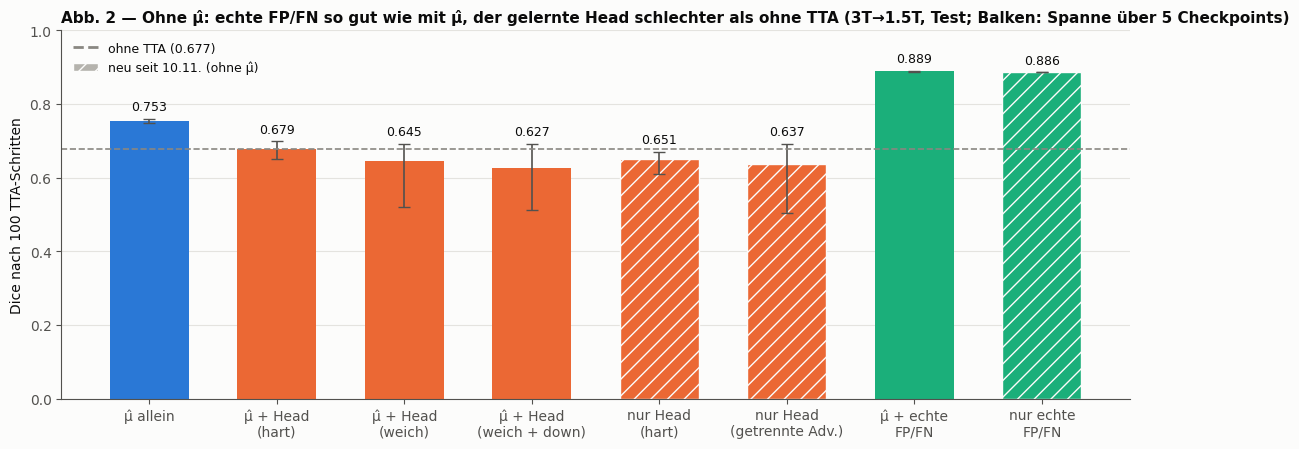

In [3]:
HEAD_RUNS = [('μ̂ allein', 'latent_tta_prenorm', C_MU, False),
             ('μ̂ + Head\n(hart)', 'latent_tta_mu_fpfnhead_w1.0', C_HEAD, False),
             ('μ̂ + Head\n(weich)', 'latent_tta_mu_fpfnheadsoft_w1.0', C_HEAD, False),
             ('μ̂ + Head\n(weich + down)', 'latent_tta_mu_fpfnheadsoftdown_w1.0', C_HEAD, False),
             ('nur Head\n(hart)', 'latent_tta_fpfnonly_head', C_HEAD, True),
             ('nur Head\n(getrennte Adv.)', 'latent_tta_fpfnonly_head_fpfnsplit', C_HEAD, True),
             ('μ̂ + echte\nFP/FN', 'latent_tta_mu_fpfn_joint_w1.0', C_ORACLE, False),
             ('nur echte\nFP/FN', 'latent_tta_fpfnonly_oracle', C_ORACLE, True)]
fig, ax = plt.subplots(figsize=(11.5, 4.6))
start = before_dice(T15)
x = np.arange(len(HEAD_RUNS))
means, lo, hi = [], [], []
for name, run, c, _ in HEAD_RUNS:
    v = after_per_ckpt(run, T15)
    means.append(np.mean(v)); lo.append(np.mean(v) - min(v)); hi.append(max(v) - np.mean(v))
bars = ax.bar(x, means, 0.62, color=[c for _, _, c, _ in HEAD_RUNS])
for b, (_, _, _, new) in zip(bars, HEAD_RUNS):
    if new:
        b.set_hatch('//'); b.set_edgecolor(SURFACE)
ax.errorbar(x, means, yerr=[lo, hi], fmt='none', ecolor=INK2, elinewidth=1.2, capsize=4)
for xi, m, h in zip(x, means, hi):
    ax.text(xi, m + h + 0.015, f'{m:.3f}', ha='center', va='bottom', fontsize=9)
ax.axhline(start, color=START, ls='--', lw=1.2)
ax.legend(handles=[Line2D([], [], color=START, ls='--', label=f'ohne TTA ({start:.3f})'),
                   mpatches.Patch(facecolor=NEUTRAL, hatch='//', edgecolor=SURFACE, label='neu seit 10.11. (ohne μ̂)')],
          loc='upper left', fontsize=9)
ax.set_xticks(x, [n for n, _, _, _ in HEAD_RUNS]); ax.grid(axis='x', visible=False)
ax.set_ylim(0, 1.0); ax.set_ylabel('Dice nach 100 TTA-Schritten')
ax.set_title('Abb. 2 — Ohne μ̂: echte FP/FN so gut wie mit μ̂, der gelernte Head schlechter als ohne TTA '
             '(3T→1.5T, Test; Balken: Spanne über 5 Checkpoints)', loc='left')
fig.tight_layout(); save(fig, '02_nur_fpfn')

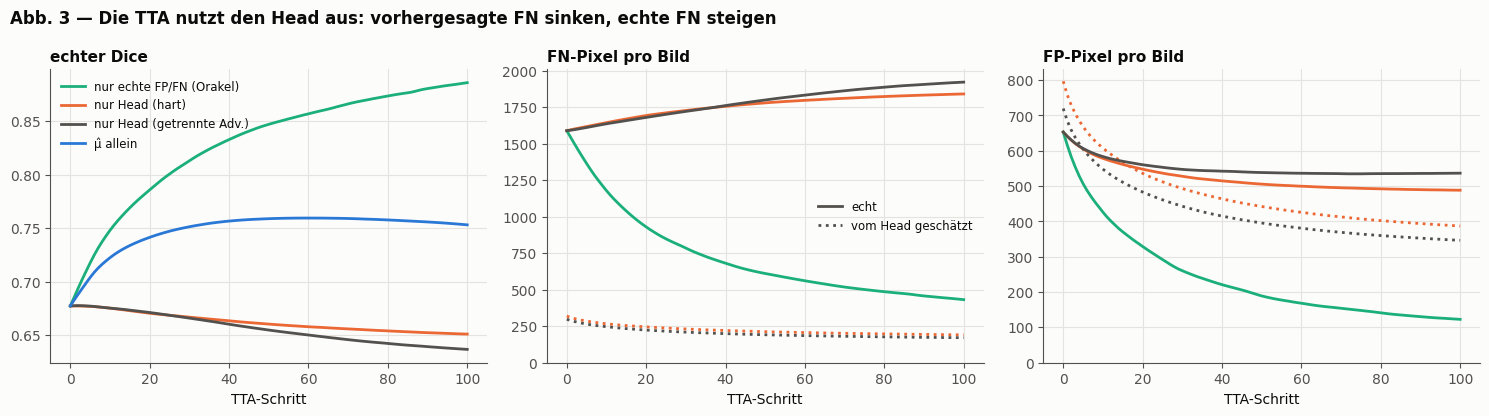

In [4]:
traj = {'nur echte FP/FN (Orakel)': (per_step_means('latent_tta_fpfnonly_oracle', T15), C_ORACLE),
        'nur Head (hart)': (per_step_means('latent_tta_fpfnonly_head', T15), C_HEAD),
        'nur Head (getrennte Adv.)': (per_step_means('latent_tta_fpfnonly_head_fpfnsplit', T15), REF),
        'μ̂ allein': (per_step_means('latent_tta_prenorm', T15), C_MU)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for name, (t, c) in traj.items():
    if 'dice_per_step' in t:
        ax.plot(t['dice_per_step'], color=c, label=name)
ax.set_title('echter Dice', loc='left'); ax.set_xlabel('TTA-Schritt'); ax.legend(fontsize=8.5)
for ax, key, name in ((axes[1], 'fn', 'FN'), (axes[2], 'fp', 'FP')):
    for run, (t, c) in traj.items():
        if f'{key}_hard_per_step' in t and run != 'μ̂ allein':
            ax.plot(t[f'{key}_hard_per_step'], color=c)
        if f'{key}_pred_per_step' in t:
            ax.plot(t[f'{key}_pred_per_step'], color=c, ls=':')
    ax.set_title(f'{name}-Pixel pro Bild', loc='left'); ax.set_xlabel('TTA-Schritt'); ax.set_ylim(bottom=0)
axes[1].legend(handles=[Line2D([], [], color=INK2, label='echt'), Line2D([], [], color=INK2, ls=':', label='vom Head geschätzt')],
               fontsize=8.5)
fig.suptitle('Abb. 3 — Die TTA nutzt den Head aus: vorhergesagte FN sinken, echte FN steigen', x=0.01, ha='left')
fig.tight_layout(); save(fig, '03_verlauf')

**Warum der Head ausgenutzt wird (Mechanismus).** Mit den echten weichen Zahlen FP = Σ p(1−g),
FN = Σ (1−p) g ist der Gradient nach p die Label-Karte selbst: Jedes Pixel erfährt, in welche Richtung es
muss. Beim gelernten Head läuft der Gradient durch dessen eigene Steigungen: über die Logits und
zusätzlich über die Features von Schicht 17 (Eingang der Norm), die sich durch die Affine an Schicht 0
verändern. (Die Features von Schicht 0 liest der Head vor der Norm, also vor der Affine — sie bleiben
während der TTA konstant.) Diese Steigungen wurden nie trainiert: Der *Wert* des Heads kann bei
Schritt 0 stimmen, seine *Steigung* in die Richtungen, die die TTA ausprobiert, ist beliebig. Die
Ausgabe des Heads durch die richtige Zahl zu ersetzen hilft auch nicht — die Richtung käme weiter vom Head.

## 3 · Warum die gelernten Heads scheitern: Generalisierung

Alle Varianten: gleiche Architektur und Swivels wie μ̂ (Schichten 0, 17 und Logits), sagen log(1+FP),
log(1+FN) mit MSE vorher; pro Schritt 30 saubere + 30 adversarial verschobene Eingabebilder (Controller
auf einen echten Dice-Abfall von 0.1). Details: `docs/fpfn_head_details.md`.

| Variante | Zielgröße | Adversary | trainiert |
|---|---|---|---|
| hart (`fpfn`) | harte Maske | einer, +∇ log(1+FP̂+FN̂) | vor 10.11. |
| weich (`fpfnsoft`) | weiche Zählung (= Größe des Orakels) | wie hart | vor 10.11. |
| weich + down (`fpfnsoftdown`) | weich | + zweiter Adversary in TTA-Richtung | vor 10.11. |
| getrennte Adversaries (`fpfnsplit`) | hart | 15 Bilder +∇FP̂, 15 +∇FN̂, eigene Controller | **neu** |
| getrennte Heads (`fpfnsepfp` + `fpfnsepfn`) | hart | zwei Netze, je eine Zahl + eigener Adversary | **neu** |

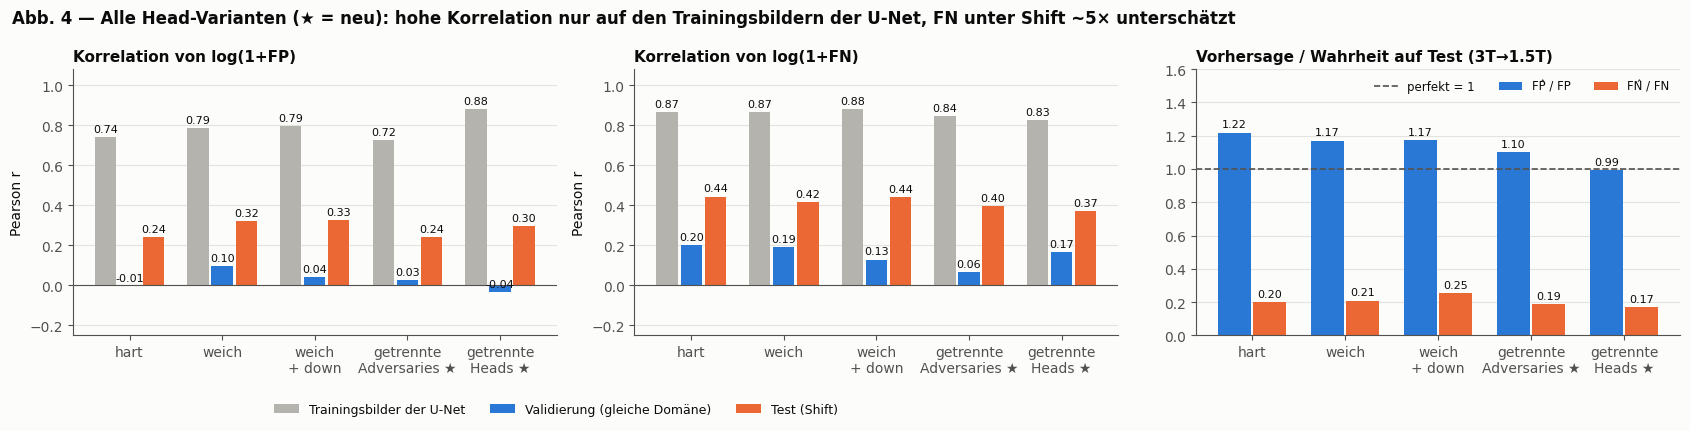

In [5]:
HEADS = [('hart', T15, 'fpfn'), ('weich', T15, 'fpfnsoft'), ('weich + down', T15, 'fpfnsoftdown'),
         ('getrennte Adv.', T15, 'fpfnsplit')]
TICK = ['hart', 'weich', 'weich\n+ down', 'getrennte\nAdversaries ★', 'getrennte\nHeads ★']
ht = head_table(HEADS)
# getrennte Heads: FP-Metriken vom FP-Head fpfnsepfp_k, FN-Metriken vom FN-Head fpfnsepfn_k
sep = head_table([('FP-Head', T15, 'fpfnsepfp'), ('FN-Head', T15, 'fpfnsepfn')])
for dom in ('train', 'val', 'test'):
    fp_row, fn_row = sep.loc[(SPLITS[T15], 'FP-Head', dom)], sep.loc[(SPLITS[T15], 'FN-Head', dom)]
    row = {c: (fp_row[c] if 'FP' in c else fn_row[c] if 'FN' in c else np.nan) for c in sep.columns}
    row.update({'U-Net Dice': fp_row['U-Net Dice'], 'n heads': fp_row['n heads']})
    ht.loc[(SPLITS[T15], 'getrennte Heads', dom), :] = pd.Series(row)
HEADS_PLOT = HEADS + [('getrennte Heads', T15, None)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.1))
DOM_C = {'train': NEUTRAL, 'val': BLUE, 'test': ORANGE}
DOM_L = {'train': 'Trainingsbilder der U-Net', 'val': 'Validierung (gleiche Domäne)', 'test': 'Test (Shift)'}
x = np.arange(len(HEADS_PLOT)); w = 0.26
for ax, metric, name in ((axes[0], 'r log FP', 'FP'), (axes[1], 'r log FN', 'FN')):
    for j, dom in enumerate(('train', 'val', 'test')):
        vals = [ht.loc[(SPLITS[T15], h, dom), metric] for h, _, _ in HEADS_PLOT]
        bars = ax.bar(x + (j - 1) * w, vals, w - 0.03, color=DOM_C[dom], label=DOM_L[dom])
        label_bars(ax, bars, fmt='{:.2f}', pad=0.015, horizontal=False)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(x, TICK); ax.set_ylim(-0.25, 1.08); ax.grid(axis='x', visible=False)
    ax.set_title(f'Korrelation von log(1+{name})', loc='left'); ax.set_ylabel('Pearson r')
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, fontsize=9, loc='lower center', ncol=3, bbox_to_anchor=(0.33, -0.04))
ax = axes[2]
for j, (metric, name, c) in enumerate((('FP_hat / FP', 'FP̂ / FP', BLUE), ('FN_hat / FN', 'FN̂ / FN', ORANGE))):
    vals = [ht.loc[(SPLITS[T15], h, 'test'), metric] for h, _, _ in HEADS_PLOT]
    bars = ax.bar(x + (j - 0.5) * 0.38, vals, 0.35, color=c, label=name)
    label_bars(ax, bars, fmt='{:.2f}', pad=0.02, horizontal=False)
ax.axhline(1, color=INK2, ls='--', lw=1.2, label='perfekt = 1')
ax.set_xticks(x, TICK); ax.grid(axis='x', visible=False); ax.set_ylim(0, 1.6)
ax.set_title('Vorhersage / Wahrheit auf Test (3T→1.5T)', loc='left'); ax.legend(fontsize=8.5, loc='upper right', ncol=3)
fig.suptitle('Abb. 4 — Alle Head-Varianten (★ = neu): hohe Korrelation nur auf den Trainingsbildern der U-Net, '
             'FN unter Shift ~5× unterschätzt', x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.05, 1, 1)); save(fig, '04_head_qualitaet')

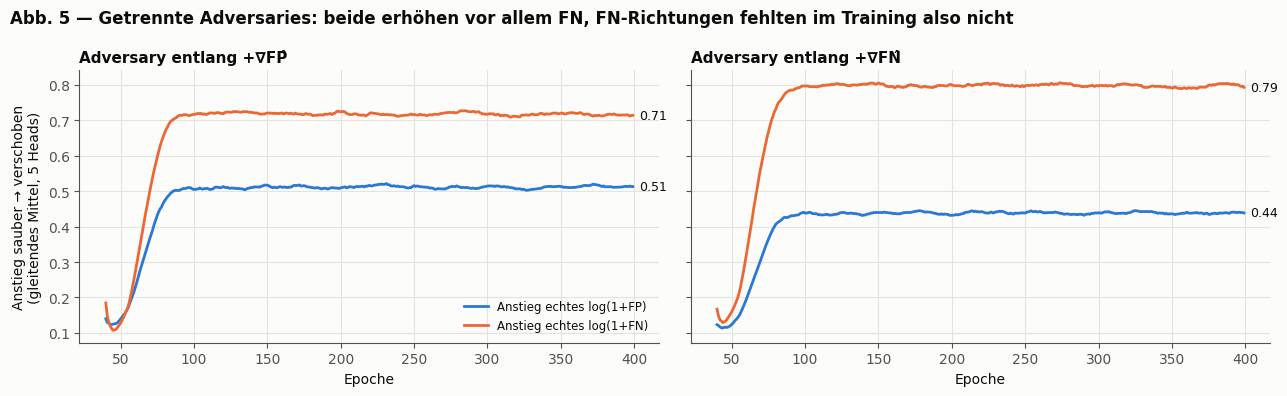

In [6]:
recs = []
for f in sorted(LOGS.glob('train_fpfnsplit_head_[0-9].log')):
    for line in open(f, errors='ignore'):
        for m in ADV_LINE.finditer(line):
            recs.append({'head': f.stem[-1], 'epoch': int(m.group(1)), 'adv': m.group(2),
                         'drop': float(m.group(4)), 'dFP': float(m.group(5)), 'dFN': float(m.group(6))})
adv = pd.DataFrame(recs)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, a, title in ((axes[0], 'FP', 'Adversary entlang +∇FP̂'), (axes[1], 'FN', 'Adversary entlang +∇FN̂')):
    d = adv[adv.adv == a].groupby('epoch')[['dFP', 'dFN']].mean().rolling(15, min_periods=1).mean()
    d = d[d.index >= 40]
    ax.plot(d.index, d['dFP'], color=BLUE, label='Anstieg echtes log(1+FP)')
    ax.plot(d.index, d['dFN'], color=ORANGE, label='Anstieg echtes log(1+FN)')
    for col in ('dFP', 'dFN'):
        ax.text(d.index[-1] + 4, d[col].iloc[-1], f'{d[col].iloc[-1]:.2f}', va='center', fontsize=9, color=INK)
    ax.set_title(title, loc='left'); ax.set_xlabel('Epoche')
axes[0].set_ylabel('Anstieg sauber → verschoben\n(gleitendes Mittel, 5 Heads)'); axes[0].legend(fontsize=8.5)
fig.suptitle('Abb. 5 — Getrennte Adversaries: beide erhöhen vor allem FN, FN-Richtungen fehlten im Training also nicht',
             x=0.01, ha='left')
fig.tight_layout(); save(fig, '05_getrennte_adversaries')

- Die Heads lernen die Fehler der U-Net auf **genau den Bildern, auf denen die U-Net trainiert wurde**;
  dort macht sie wenige und andere Fehler (Dice 0.92–0.95). Auf neuen Bildern derselben Domäne r ≈ 0.
- Unter Shift unterschätzt jede Variante FN ~5×, FP wird etwa richtig oder überschätzt — die
  Reihenfolge der Fehlerarten ist vertauscht (wahr: FN ≫ FP).
- Weder getrennte Adversaries noch getrennte Heads ändern daran etwas. Unsere Hypothese vom 10.11.
  („der gemeinsame Adversary trainiert FN-Richtungen zu wenig“) ist widerlegt (Abb. 5).

## 4 · Nebenbefund: die Lernrate war früh eingefroren (Heads *und* μ̂-Predictor)

`ReduceLROnPlateau` (Patience 20, Faktor 0.1) überwacht `val_loss` = sauberer Loss + ab Epoche 41 der
Adversary-Loss. `val_loss` springt, sobald der Adversary zugeschaltet wird, und fällt nie mehr unter sein
frühes Minimum → vier Kürzungen, lr 3.16e-5 → 3.16e-9 bis Epoche ~100. Rekonstruiert aus dem geloggten
`val_loss` (wandb, in `results/` gespeichert) und mit der lr in den Checkpoints abgeglichen.

lr in den gespeicherten Checkpoints — FP/FN-Heads: ['3.16e-09'] | μ̂-Predictor: ['3.16e-09']


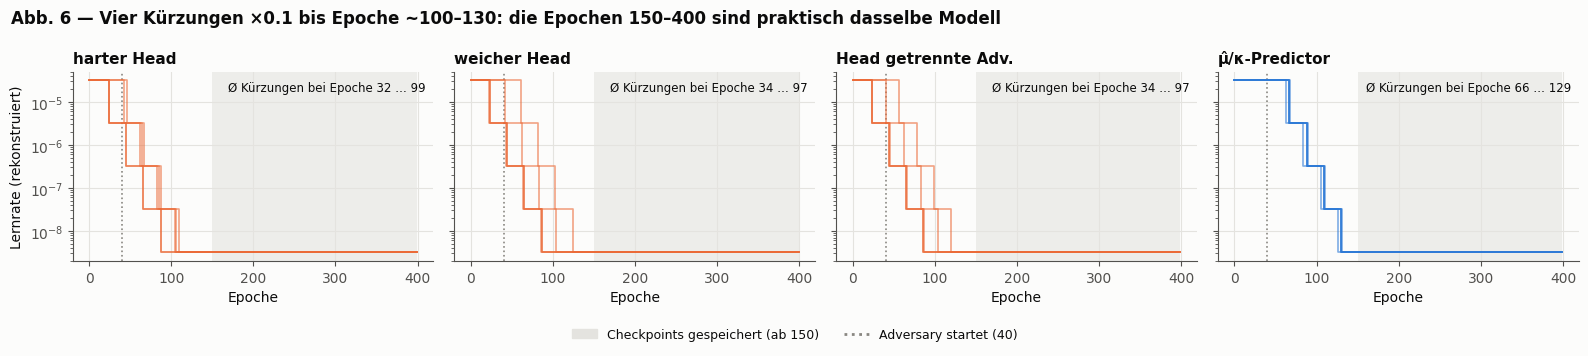

In [7]:
LR0, CKPT_START, ADV_START = 3.16e-5, 150, 40
def lr_trace(vals):
    opt = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=LR0)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', patience=20)
    out = []
    for v in vals:
        out.append(opt.param_groups[0]['lr'])
        sch.step(float(v))
    return np.array(out)

def ckpt_lr(files):
    return sorted({f"{torch.load(f, map_location='cpu', weights_only=False)['optimizer_states'][0]['param_groups'][0]['lr']:.2e}"
                   for f in files})

hist = pd.read_csv(RES / 'fpfn_head' / 'wandb_val_history.csv')
mu_hist = pd.read_csv(RES / 'wandb' / 'mu_predictor_threet-to-onepointfivet_val_history.csv')
print('lr in den gespeicherten Checkpoints — FP/FN-Heads:', ckpt_lr((ROOT / 'pre-trained' / 'fpfn-heads').glob(f'pmri_{T15}_*.ckpt')),
      '| μ̂-Predictor:', ckpt_lr((ROOT / 'pre-trained' / 'score-predictors' / 'pre_norm_with_logits').glob(f'pmri_{T15}_*cleanHalf_*val-epoch=*.ckpt')))
PANELS = [('harter Head', hist[(hist.split == T15) & (hist.variant == 'fpfn')], C_HEAD),
          ('weicher Head', hist[(hist.split == T15) & (hist.variant == 'fpfnsoft')], C_HEAD),
          ('Head getrennte Adv.', hist[(hist.split == T15) & (hist.variant == 'fpfnsplit')], C_HEAD),
          ('μ̂/κ-Predictor', mu_hist, C_MU)]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3), sharey=True)
for ax, (name, sub, c) in zip(axes, PANELS):
    ax.axvspan(CKPT_START, sub.epoch.max(), color=GRID, alpha=0.6, lw=0)
    ax.axvline(ADV_START, color=START, ls=':', lw=1.2)
    cuts = []
    for k, h in sub.groupby('seed'):
        h = h.sort_values('epoch')
        lr = lr_trace(h.val_loss)
        ax.step(h.epoch, lr, where='post', color=c, lw=1.2, alpha=0.6)
        cuts.append(h.epoch.to_numpy()[np.nonzero(np.diff(lr))[0] + 1])
    ax.set_yscale('log'); ax.set_title(name, loc='left'); ax.set_xlabel('Epoche')
    ax.text(0.98, 0.95, f'Ø Kürzungen bei Epoche {np.mean([c_[0] for c_ in cuts]):.0f} … {np.mean([c_[-1] for c_ in cuts]):.0f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8.5)
axes[0].set_ylabel('Lernrate (rekonstruiert)')
fig.legend(handles=[mpatches.Patch(color=GRID, label='Checkpoints gespeichert (ab 150)'),
                    Line2D([], [], color=START, ls=':', label='Adversary startet (40)')],
           fontsize=9, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Abb. 6 — Vier Kürzungen ×0.1 bis Epoche ~100–130: die Epochen 150–400 sind praktisch dasselbe Modell',
             x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.04, 1, 1)); save(fig, '06_lr_scheduler')

- Die Validierungskorrelation der Heads ist über das *ganze* Training niedrig (auch vor den Kürzungen);
  ein früherer Checkpoint wäre nicht besser gewesen — der Scheduler ist nicht die Ursache der schlechten Heads.
- Für **μ̂** ist er aber relevant: Alle bisherigen TTA-Ergebnisse nutzen μ̂-Predictoren, die effektiv
  nur ~100–130 Epochen trainiert wurden, also kaum Adversary-Epochen mit brauchbarer Lernrate hatten. Ein
  Neutraining mit dem Scheduler auf `val_loss_clean` (Option für die Heads schon eingebaut) ist ein
  offener, billiger Test.

## 5 · Pseudo-Label-Orakel: Wie gut muss eine Label-Karte ĝ sein? (exp9)

Das Orakel-Ziel, aber statt der Labels eine feste, absichtlich verschlechterte Karte ĝ (kein Gradient
durch ĝ): FP = Σ p(1−ĝ), FN = Σ (1−p)ĝ. So würde ein dichter Fehlerkarten-Head — oder jede andere Quelle
für Pseudo-Labels — eingesetzt. **recall r:** Anteil der U-Net-Fehler, die in ĝ korrigiert sind
(zusammenhängende Flecken von ~16 px); r = 1 ist das Orakel, r = 0 ist ĝ = Maske vor der TTA.
**morph ±3:** Label um 3 px vergrößert / verkleinert. Ein Seed pro Stufe.

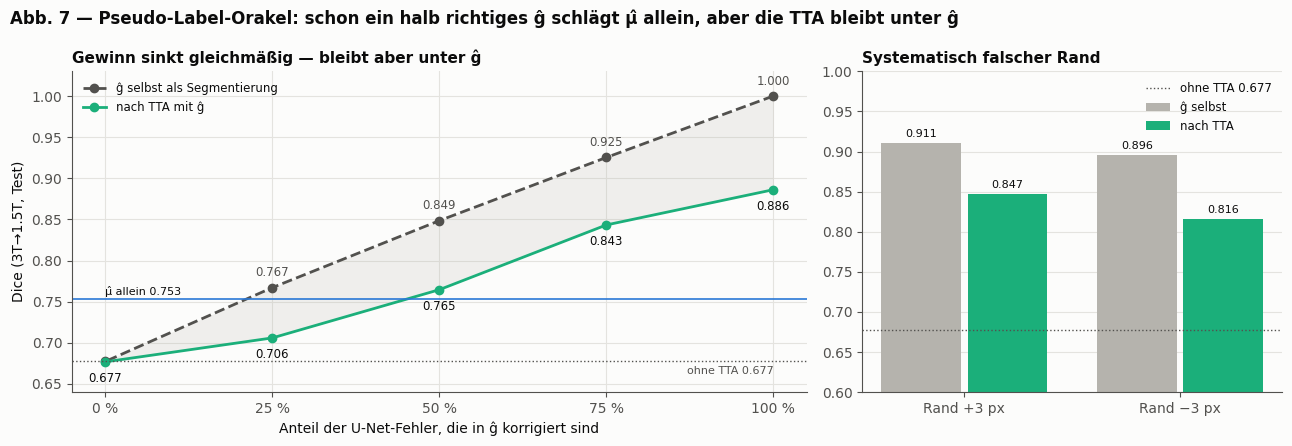

In [8]:
PSEUDO = [(1.0, 'latent_tta_pseudo_recall1.0'), (0.75, 'latent_tta_pseudo_recall0.75'), (0.5, 'latent_tta_pseudo_recall0.5'),
          (0.25, 'latent_tta_pseudo_recall0.25'), (0.0, 'latent_tta_pseudo_recall0.0')]
MORPH = [('Rand +3 px', 'latent_tta_pseudo_morph3'), ('Rand −3 px', 'latent_tta_pseudo_morph-3')]
def pseudo_stats(run):
    e = evals(run, T15)[0]
    return float(e['pseudo_dice'].mean()), float(e['dice_after'].float().mean()), float(e['dice_before'].float().mean())
P = [(r, *pseudo_stats(run)) for r, run in PSEUDO if tta_files(run, T15)]
M = [(n, *pseudo_stats(run)) for n, run in MORPH if tta_files(run, T15)]
start = P[0][3]
mu_only = np.mean(after_per_ckpt('latent_tta_prenorm', T15))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.4, 0.8]})
ax = axes[0]
r, g, a = np.array([p[0] for p in P]), np.array([p[1] for p in P]), np.array([p[2] for p in P])
ax.fill_between(r, a, g, color=NEUTRAL, alpha=0.18, lw=0)
ax.plot(r, g, color=INK2, ls='--', marker='o', label='ĝ selbst als Segmentierung')
ax.plot(r, a, color=C_ORACLE, marker='o', label='nach TTA mit ĝ')
for ri, gi, ai in zip(r, g, a):
    ax.text(ri, ai - 0.012, f'{ai:.3f}', ha='center', va='top', fontsize=8.5, color=INK)
    if ri > 0:
        ax.text(ri, gi + 0.01, f'{gi:.3f}', ha='center', va='bottom', fontsize=8.5, color=INK2)
ax.axhline(start, color=INK2, lw=1, ls=':'); ax.text(1.0, start - 0.006, f'ohne TTA {start:.3f}', ha='right', va='top', fontsize=8, color=INK2)
ax.axhline(mu_only, color=C_MU, lw=1.2); ax.text(0.0, mu_only + 0.005, f'μ̂ allein {mu_only:.3f}', fontsize=8, color=INK)
ax.set_xlabel('Anteil der U-Net-Fehler, die in ĝ korrigiert sind'); ax.set_ylabel('Dice (3T→1.5T, Test)')
ax.set_xticks(r, [f'{int(100 * x)} %' for x in r]); ax.set_ylim(0.64, 1.03)
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Gewinn sinkt gleichmäßig — bleibt aber unter ĝ', loc='left')
ax = axes[1]
x = np.arange(len(M))
b1 = ax.bar(x - 0.2, [m[1] for m in M], 0.37, color=NEUTRAL, label='ĝ selbst')
b2 = ax.bar(x + 0.2, [m[2] for m in M], 0.37, color=C_ORACLE, label='nach TTA')
label_bars(ax, list(b1) + list(b2), fmt='{:.3f}', pad=0.005, horizontal=False)
ax.axhline(start, color=INK2, lw=1, ls=':', label=f'ohne TTA {start:.3f}')
ax.set_xticks(x, [m[0] for m in M]); ax.set_ylim(0.6, 1.0); ax.grid(axis='x', visible=False)
ax.legend(fontsize=8.5, loc='upper right'); ax.set_title('Systematisch falscher Rand', loc='left')
fig.suptitle('Abb. 7 — Pseudo-Label-Orakel: schon ein halb richtiges ĝ schlägt μ̂ allein, aber die TTA bleibt unter ĝ',
             x=0.01, ha='left')
fig.tight_layout(); save(fig, '07_pseudo_label_orakel')

- **Der Mechanismus trägt:** kein Absturz, der Gewinn fällt gleichmäßig mit der Qualität von ĝ;
  r = 100 % reproduziert das exp8-Orakel exakt (Plausibilitätsprüfung).
- **Aber:** Die TTA setzt nur 32–73 % der Verbesserung um, die schon in ĝ steckt. Eine Quelle für ein
  gutes ĝ wäre allein schon die bessere Segmentierung. TTA bringt nur dann etwas, wenn sie Korrekturen
  aus einem *teilweisen* ĝ (nur sichere Pixel) auf den Rest überträgt — noch nicht getestet. Die Kurven
  sind bei Schritt 100 noch nicht am Ende.

## 6 · Wo selbst das FP/FN-Orakel scheitert: verpasste Prostatas

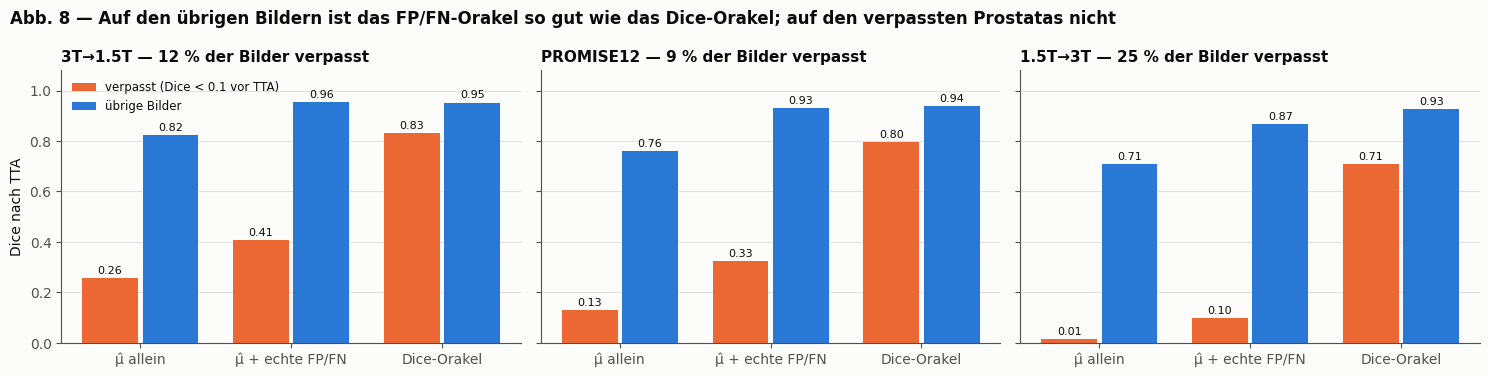

In [9]:
S2 = [('μ̂ allein', 'latent_tta_prenorm'), ('μ̂ + echte FP/FN', 'latent_tta_mu_fpfn_joint_w1.0'),
      ('Dice-Orakel', 'latent_tta_oracle')]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, s in zip(axes, SPLIT_ORDER):
    miss_v, rest_v, frac = [], [], None
    for name, run in S2:
        es = evals(run, s)
        b = torch.cat([e['dice_before'].float() for e in es]); a = torch.cat([e['dice_after'].float() for e in es])
        m = b < 0.1
        frac = 100 * float(m.float().mean())
        miss_v.append(float(a[m].mean())); rest_v.append(float(a[~m].mean()))
    x = np.arange(len(S2))
    b1 = ax.bar(x - 0.2, miss_v, 0.37, color=ORANGE, label='verpasst (Dice < 0.1 vor TTA)')
    b2 = ax.bar(x + 0.2, rest_v, 0.37, color=BLUE, label='übrige Bilder')
    label_bars(ax, list(b1) + list(b2), fmt='{:.2f}', pad=0.01, horizontal=False)
    ax.set_xticks(x, [n for n, _ in S2]); ax.set_ylim(0, 1.08); ax.grid(axis='x', visible=False)
    ax.set_title(f'{SPLITS[s]} — {frac:.0f} % der Bilder verpasst', loc='left')
axes[0].set_ylabel('Dice nach TTA'); axes[0].legend(loc='upper left', fontsize=8.5)
fig.suptitle('Abb. 8 — Auf den übrigen Bildern ist das FP/FN-Orakel so gut wie das Dice-Orakel; auf den verpassten Prostatas nicht',
             x=0.01, ha='left')
fig.tight_layout(); save(fig, '08_verpasste_prostatas')

Bei einer verpassten Prostata gilt FP + FN = |P| + |G|. Die falsche Maske wegzuräumen senkt das auf |G|,
und von dort senkt keine *kleine* Änderung den Wert weiter: Die **leere Maske ist ein lokales Minimum**
von log(1+FP+FN). Diese Bilder hatten ohnehin Dice ≈ 0, das Leeren kostet also nichts — aber eine falsch
platzierte Maske lässt sich so nicht *verschieben*. Das ist der Großteil der Restlücke auf 1.5T→3T
(25 % verpasst). Für ein lokales FP/FN-Ziel außer Reichweite → braucht eine Erkennung auf Bildebene oder
einen Größen-Prior, keine Adaptation.

## 7 · Literatur: Wer hat FP / FN (oder Fehler) schon vorhergesagt?

Ausführlich, inkl. „was wir übernehmen können“: [`docs/literatur_signal.md`](../../../../docs/literatur_signal.md).
Teils nur aus Abstracts, Volltexte noch zu prüfen.

| Arbeit | Sagt vorher | Genutzt für | Unterschied zu uns |
|---|---|---|---|
| Kohlberger et al., MICCAI 2012 | Segmentierungsfehler (SVM-Regression, handgebaute Merkmale) | Qualitätskontrolle | segmentiererunabhängige Formmerkmale |
| Robinson et al., MICCAI 2018 | Dice pro Fall (12 880 Trainingsfälle) | Qualitätskontrolle | ~30× mehr Daten; ohne Labels ~5× größerer Fehler |
| Liu et al., ICCV 2019 (Alarm System) | Dice **nur aus der Maskenform** (VAE) | Qualitätskontrolle über Datensätze | Eingabe nicht geshiftet, nicht über Features austricksbar |
| Zhang et al., MedIA 2022 (DEP-Net) | **getrennte FP- und FN-Karten** pro Pixel | korrigiert Pseudo-Labels (semi-supervised) | dichte Karte, als festes Pseudo-Label genutzt |
| Qiu et al., MICCAI 2023 (QCResUNet) | Dice + NSD **und** Fehlerkarte pro Voxel | Qualitätskontrolle | Eingabe Bild + Maske, Skalar + Karte gemeinsam |
| SegAE 2026 / arXiv 2606.01753 | Qualität | Qualitätskontrolle | Trainingsmasken aus **frühen Checkpoints** + synthetischen Störungen |
| Zenk et al., MedIA 2025 | Benchmark Fehlschlag-Erkennung | Qualitätskontrolle unter Shift | **Pairwise Dice im Ensemble** schlägt gelernte Regressoren |
| Karani et al., MedIA 2021 | Denoising-Autoencoder nur auf Masken | **TTA**: DAE-Ausgabe = festes Pseudo-Label, Dice-Loss | genau unsere exp9-Struktur, Prior domänenunabhängig |
| Bateson et al., MICCAI 2022 | — (Formmomente: Größe, Schwerpunkt) | **TTA** mit Form-Prior, u. a. Prostata | Größe allein ist bei uns schon stark (Größen-Orakel) |
| Zhou et al., MICCAI 2025 (TEGDA) | Dice-Ersatz aus Dropout-Übereinstimmung | **TTA**: gewichtet / wählt Pseudo-Labels | Qualitätsschätzung ohne ihren Gradienten genutzt |
| Czarnecki 2017 (Sobolev) / Zhang 2021 (ARM-LL) | — | *Ableitungen* eines Netzes / Loss-Netz für Adaptation trainieren | würde „Steigungen nie trainiert“ angehen |

**Drei wiederkehrende Unterschiede:** (1) vielfältige Fehler im Training (viele Modelle, Checkpoints,
Störungen) statt einer U-Net auf ihren eigenen Trainingsbildern; (2) dichte Karten oder normierte Maße
statt absoluter Zahlen; (3) wo eine Schätzung die Adaptation steuert, wird sie zum festen Pseudo-Label
oder Gewicht — niemand optimiert über den Gradienten eines gelernten Qualitätsprädiktors.

## 8 · Vorschlag und Fragen für heute

**Vorschlag: zurück zu μ̂ als einsetzbarem Signal; FP/FN nur noch als Struktur (Pseudo-Label ĝ).**

| # | Schritt | Training nötig? | Grundlage |
|---|---|---|---|
| 1 | μ̂ als **Auswahl- / Stopp-Signal** (pro Bild bester Schritt nach μ̂, Zurückrollen wenn μ̂ fällt, Bilder auslassen) + Dropout-Übereinstimmung als label-freie Baseline | nein | TEGDA, Karani, Zenk |
| 2 | μ̂ + **Größen- / Form-Prior** aus Quellstatistik (untere Grenze für Σp gegen das Minimum der leeren Maske) | nein | Bateson; unser Größen-Orakel (0.783) |
| 3 | ĝ aus einem **Denoising-Autoencoder nur auf Masken** im bestehenden Pseudo-Label-Pfad (`fpfn_source=pseudo`), optional nur auf sicheren Pixeln | klein (DAE auf Masken) | Karani, Post-DAE, DPL; exp9 |
| 4 | **μ̂ neu trainieren**: Scheduler auf dem sauberen Loss, Trainingsmasken aus frühen U-Net-Checkpoints + Shift-Augmentierungen; Ablation Swivels = nur Logits | ja | SegAE, Alarm System |
| 5 | Ausblick: Ableitungen von μ̂ trainieren (Sobolev) oder μ̂ meta-lernen (ARM-LL) | ja, teuer | Czarnecki, Zhang |

Der dichte FP/FN-Fehlerkarten-Head (seit 12.11. vorgemerkt) wird zurückgestellt: Er hat dasselbe Problem
mit den Trainingsdaten wie die skalaren Heads, und exp9 zeigt, dass selbst eine perfekte Karte direkt
besser genutzt wäre.

**Fragen:**
1. Ist es ok, den gelernten (skalaren) FP/FN-Head fallen zu lassen und zu μ̂ zurückzugehen, mit FP/FN als Pseudo-Label-Struktur?
2. Passt es in die Arbeit, μ̂ zur Auswahl / zum Stoppen zu nutzen statt (nur) als Gradientenziel?
3. Ist ein Größen- / Form-Prior als zusätzliches label-freies Wissen (nur Quellstatistik) akzeptabel?
4. Priorität zwischen DAE-Pseudo-Labels (3) und μ̂-Neutraining (4)?

## Anhang · Tabellen

In [10]:
ALL = [('μ̂ allein', 'latent_tta_prenorm'), ('Dice-Orakel', 'latent_tta_oracle'),
       ('Größen-Orakel', 'latent_tta_mu_size_w1.0'),
       ('μ̂ + echte FP/FN getrennt', 'latent_tta_mu_fpfn_w1.0'), ('μ̂ + echte FP/FN gemeinsam', 'latent_tta_mu_fpfn_joint_w1.0'),
       ('nur echte FP/FN ★', 'latent_tta_fpfnonly_oracle'),
       ('μ̂ + Head (hart)', 'latent_tta_mu_fpfnhead_w1.0'), ('μ̂ + Head (weich)', 'latent_tta_mu_fpfnheadsoft_w1.0'),
       ('μ̂ + Head (weich + down)', 'latent_tta_mu_fpfnheadsoftdown_w1.0'),
       ('nur Head (hart) ★', 'latent_tta_fpfnonly_head'), ('nur Head (getrennte Adv.) ★', 'latent_tta_fpfnonly_head_fpfnsplit')] + \
      [(f'Pseudo-Label {int(100 * r)} % ★', run) for r, run in PSEUDO] + [(f'Pseudo-Label {n} ★', run) for n, run in MORPH]
cols = ['before', 'after', 'after ± (ckpts)', 'best step', 'worse %', 'empty %', 'FP before', 'FP after', 'FN before', 'FN after',
        'FP_hat before', 'FP_hat after', 'FN_hat before', 'FN_hat after', 'n ckpts']
tab = tta_table(ALL, cols=cols)
tab.columns = ['vorher', 'nachher', '± Checkpoints', 'bester Schritt', 'schlechter %', 'leer %', 'FP vorher', 'FP nachher',
               'FN vorher', 'FN nachher', 'FP̂ vorher', 'FP̂ nachher', 'FN̂ vorher', 'FN̂ nachher', 'Checkpoints']
fmt = {c: '{:.3f}' for c in tab.columns}
fmt.update({c: '{:.0f}' for c in tab.columns if c.startswith(('FP', 'FN')) or c == 'Checkpoints'})
fmt.update({c: '{:.1f}' for c in tab.columns if '%' in c})
tab.style.format(fmt, na_rep='–')

,,vorher,nachher,± Checkpoints,bester Schritt,schlechter %,leer %,FP vorher,FP nachher,FN vorher,FN nachher,FP̂ vorher,FP̂ nachher,FN̂ vorher,FN̂ nachher,Checkpoints
split,run,,,,,,,,,,,,,,,
3T→1.5T,μ̂ allein,0.677,0.753,0.004,0.783,25.8,–,–,–,–,–,–,–,–,–,5
PROMISE12,μ̂ allein,0.642,0.702,0.011,0.717,19.2,–,–,–,–,–,–,–,–,–,5
1.5T→3T,μ̂ allein,0.526,0.538,0.001,0.546,14.5,–,–,–,–,–,–,–,–,–,5
3T→1.5T,Dice-Orakel,0.677,0.937,0.000,0.938,0.0,–,–,–,–,–,–,–,–,–,5
PROMISE12,Dice-Orakel,0.642,0.926,0.000,0.926,0.0,–,–,–,–,–,–,–,–,–,5
1.5T→3T,Dice-Orakel,0.526,0.874,0.000,0.874,0.0,–,–,–,–,–,–,–,–,–,5
3T→1.5T,Größen-Orakel,0.677,0.783,0.004,0.793,7.5,0.0,653,804,1590,796,–,–,–,–,5
PROMISE12,Größen-Orakel,0.642,0.742,0.013,0.755,9.6,0.0,1013,1117,1995,1101,–,–,–,–,5
1.5T→3T,Größen-Orakel,0.526,0.590,0.001,0.602,10.8,0.0,1621,1695,2069,1730,–,–,–,–,5


In [11]:
heads_all = head_table(HEADS + [('FP-Head (getrennt)', T15, 'fpfnsepfp'), ('FN-Head (getrennt)', T15, 'fpfnsepfn')])
heads_all.style.format('{:.3f}', na_rep='–')